In [2]:
%pip install yfinance

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ------------------------------- -------- 1.6/2.0 MB 9.6 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 7.4 MB/s  0:00:00

   -------- ------------------------------- 1/5 [websockets]
   -------- ------------------------------- 1/5 [websockets]
   -------- ------------------------------- 1/5 [websockets]
   ---------------- ----------------------- 2/5 [peewee]
   ---------------- ----------------------- 2/5 [peewee]
   ---------------- ----------------------- 2/5 [peewee]
   ---------------- ----------------------- 2/5 [peewee]
   ---------------- ----------------------- 2/5 [peewee]
   ---------------- ----------------------- 2/5 [peewee]
   ------------------------ --------------- 3/5 [curl_cffi]
   ------------------------ --------------- 3/5 [curl_cffi]
   ------------------------ --------------- 3/5 [curl_cffi]
   -------------------------------- ------- 4/5 [yfinance]
   --------------

In [3]:

import yfinance as yf
import pandas as pd

# Assets for our quantitative finance analysis
tickers = ["SPY", "IEF", "GLD"]

# Download historical daily market prices
prices_raw = yf.download(
    tickers=tickers,
    start="2007-12-01",
    end="2026-01-01",
    interval="1d",
    auto_adjust=True,
    group_by="ticker",
    progress=False
)

print("yfinance version:", yf.__version__)
print("Dataset shape:", prices_raw.shape)

print("\nDate range:")
print(prices_raw.index.min())
print(prices_raw.index.max())

print("\nAvailable columns:")
print(prices_raw.columns)

display(prices_raw.head())



1 Failed download:
['GLD']: OperationalError('database is locked')


yfinance version: 1.7.0
Dataset shape: (4549, 16)

Date range:
2007-12-03 00:00:00
2025-12-31 00:00:00

Available columns:
MultiIndex([('GLD',      'Open'),
            ('GLD',      'High'),
            ('GLD',       'Low'),
            ('GLD',     'Close'),
            ('GLD', 'Adj Close'),
            ('GLD',    'Volume'),
            ('SPY',      'Open'),
            ('SPY',      'High'),
            ('SPY',       'Low'),
            ('SPY',     'Close'),
            ('SPY',    'Volume'),
            ('IEF',      'Open'),
            ('IEF',      'High'),
            ('IEF',       'Low'),
            ('IEF',     'Close'),
            ('IEF',    'Volume')],
           names=['Ticker', 'Price'])


Ticker      GLD                                         SPY              \
Price      Open High Low Close Adj Close Volume        Open        High   
Date                                                                      
2007-12-03  NaN  NaN NaN   NaN       NaN    NaN  104.734377  104.918130   
2007-12-04  NaN  NaN NaN   NaN       NaN    NaN  103.653016  104.274955   
2007-12-05  NaN  NaN NaN   NaN       NaN    NaN  104.550597  105.448181   
2007-12-06  NaN  NaN NaN   NaN       NaN    NaN  105.045363  106.868798   
2007-12-07  NaN  NaN NaN   NaN       NaN    NaN  107.017196  107.073738   

Ticker                                               IEF             \
Price              Low       Close     Volume       Open       High   
Date                                                                  
2007-12-03  104.098289  104.373924  146430400  55.249484  55.249484   
2007-12-04  103.405647  103.440987  136533900  55.117696  55.130248   
2007-12-05  104.479927  105.172546  171130000  54.847926  55.011067   
2007-12-06  105.002959  106.677971  154457400  54.716125  54.766325   
2007-12-07  106.402320  106.656754  148980100  54.421210  54.421210   

Ticker                                    
Price             Low      Close  Volume  
Date                                      
2007-12-03  54.841622  54.985939  214700  
2007-12-04  54.822785  55.036125  196800  
2007-12-05  54.766351  54.829098  284600  
2007-12-06  54.471409  54.540432  217900  
2007-12-07  54.088642  54.189041  193000

In [4]:

# Retry the failed GLD download without multithreading
gld = yf.download(
    tickers="GLD",
    start="2007-12-01",
    end="2026-01-01",
    interval="1d",
    auto_adjust=True,
    threads=False,
    progress=False
)

print("GLD shape:", gld.shape)
print("\nMissing values:")
print(gld.isna().sum())

display(gld.head())
display(gld.tail())


GLD shape: (4549, 5)

Missing values:
Price   Ticker
Close   GLD       0
High    GLD       0
Low     GLD       0
Open    GLD       0
Volume  GLD       0
dtype: int64


Price,Close,High,Low,Open,Volume
Ticker,GLD,GLD,GLD,GLD,GLD
Date,,,,,
2007-12-03,78.279999,78.300003,77.300003,77.389999,6265700
2007-12-04,79.400002,79.620003,78.570000,78.629997,7721900
2007-12-05,78.629997,79.250000,78.190002,79.250000,7685300
2007-12-06,79.370003,79.650002,77.800003,77.919998,6840200
2007-12-07,78.599998,79.599998,78.190002,79.010002,8328500


Price,Close,High,Low,Open,Volume
Ticker,GLD,GLD,GLD,GLD,GLD
Date,,,,,
2025-12-24,411.929993,412.630005,408.829987,412.250000,6718400
2025-12-26,416.739990,418.450012,414.750000,416.480011,10476200
2025-12-29,398.600006,403.760010,395.329987,403.660004,20679200
2025-12-30,398.890015,403.799988,398.559998,403.600006,10179000
2025-12-31,396.309998,400.130005,395.589996,398.600006,10194700


In [5]:

# Combine adjusted closing prices for all three ETFs

daily_close = pd.DataFrame({
    "SPY": prices_raw[("SPY", "Close")],
    "IEF": prices_raw[("IEF", "Close")],
    "GLD": gld[("Close", "GLD")]
})

daily_close = daily_close.sort_index()

# Data quality checks
print("Dataset shape:", daily_close.shape)

print("\nDate range:")
print(daily_close.index.min())
print(daily_close.index.max())

print("\nMissing values:")
print(daily_close.isna().sum())

print("\nDuplicate dates:",
      daily_close.index.duplicated().sum())

display(daily_close.head())


Dataset shape: (4549, 3)

Date range:
2007-12-03 00:00:00
2025-12-31 00:00:00

Missing values:
SPY    0
IEF    0
GLD    0
dtype: int64

Duplicate dates: 0


,SPY,IEF,GLD
Date,,,
2007-12-03,104.373924,54.985939,78.279999
2007-12-04,103.440987,55.036125,79.400002
2007-12-05,105.172546,54.829098,78.629997
2007-12-06,106.677971,54.540432,79.370003
2007-12-07,106.656754,54.189041,78.599998


In [6]:

# Convert daily prices into monthly closing prices

monthly_prices = daily_close.resample("MS").last()

print("Monthly dataset shape:", monthly_prices.shape)

print("\nDate range:")
print(monthly_prices.index.min())
print(monthly_prices.index.max())

print("\nMissing values:")
print(monthly_prices.isna().sum())

print("\nFirst 5 months:")
display(monthly_prices.head())

print("\nLast 5 months:")
display(monthly_prices.tail())


Monthly dataset shape: (217, 3)

Date range:
2007-12-01 00:00:00
2025-12-01 00:00:00

Missing values:
SPY    0
IEF    0
GLD    0
dtype: int64

First 5 months:


,SPY,IEF,GLD
Date,,,
2007-12-01,103.883461,54.797134,82.459999
2008-01-01,97.602509,56.636089,91.400002
2008-02-01,95.080208,57.338001,96.180000
2008-03-01,94.229973,58.104763,90.410004
2008-04-01,98.721214,56.700130,86.650002



Last 5 months:


,SPY,IEF,GLD
Date,,,
2025-08-01,636.400696,91.869751,318.070007
2025-09-01,659.069519,92.467934,355.470001
2025-10-01,674.780029,93.125603,368.119995
2025-11-01,676.095825,94.045815,387.880005
2025-12-01,676.635010,93.329941,396.309998


In [7]:

# Calculate monthly ETF returns (%)

monthly_returns = (
    monthly_prices
    .pct_change(fill_method=None)
    .mul(100)
)

# Keep the analysis period: 2008–2025
monthly_returns = monthly_returns.loc[
    "2008-01-01":"2025-12-01"
].copy()

print("Monthly returns shape:", monthly_returns.shape)

print("\nDate range:")
print(monthly_returns.index.min())
print(monthly_returns.index.max())

print("\nMissing values:")
print(monthly_returns.isna().sum())

print("\nFirst 5 months:")
display(monthly_returns.head().round(2))

print("\nLast 5 months:")
display(monthly_returns.tail().round(2))


Monthly returns shape: (216, 3)

Date range:
2008-01-01 00:00:00
2025-12-01 00:00:00

Missing values:
SPY    0
IEF    0
GLD    0
dtype: int64

First 5 months:


,SPY,IEF,GLD
Date,,,
2008-01-01,-6.05,3.36,10.84
2008-02-01,-2.58,1.24,5.23
2008-03-01,-0.89,1.34,-6.00
2008-04-01,4.77,-2.42,-4.16
2008-05-01,1.51,-1.78,0.92



Last 5 months:


,SPY,IEF,GLD
Date,,,
2025-08-01,2.05,1.65,4.99
2025-09-01,3.56,0.65,11.76
2025-10-01,2.38,0.71,3.56
2025-11-01,0.19,0.99,5.37
2025-12-01,0.08,-0.76,2.17


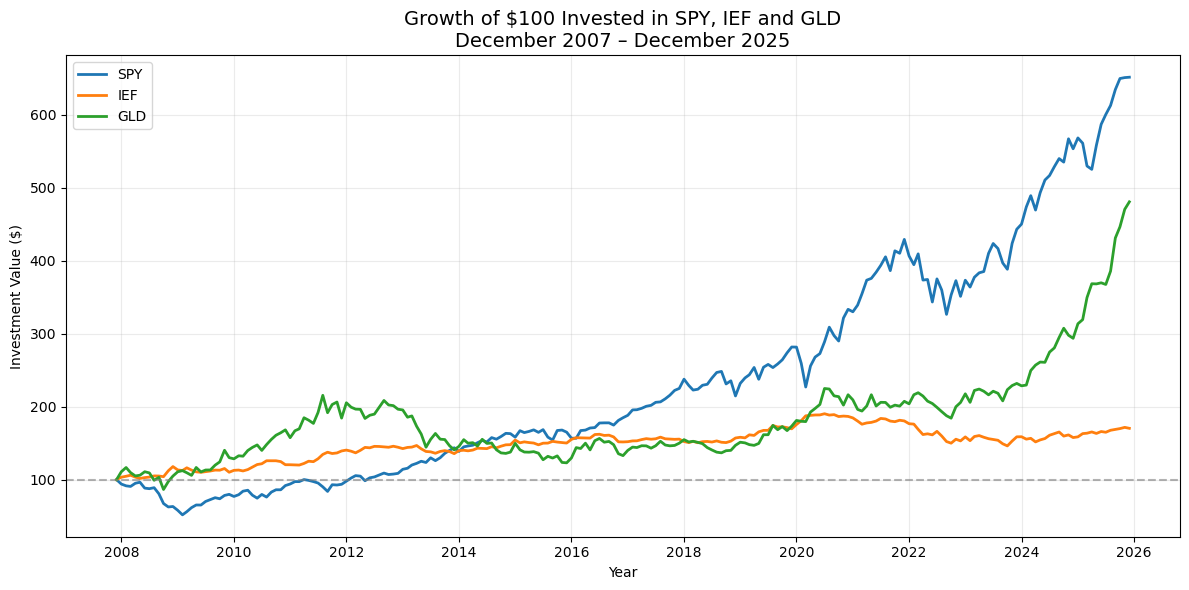

Final value of $100 invested:


,SPY,IEF,GLD
Date,,,
2025-12-01,651.34,170.32,480.61


In [8]:

import matplotlib.pyplot as plt
from pathlib import Path

# Normalize every ETF to $100 in December 2007
initial_prices = monthly_prices.iloc[0]

growth_index = (
    monthly_prices / initial_prices
) * 100

# Visualize cumulative investment growth
fig, ax = plt.subplots(figsize=(12, 6))

for ticker in ["SPY", "IEF", "GLD"]:
    ax.plot(
        growth_index.index,
        growth_index[ticker],
        label=ticker,
        linewidth=2
    )

ax.axhline(
    100,
    color="gray",
    linestyle="--",
    alpha=0.6
)

ax.set_title(
    "Growth of $100 Invested in SPY, IEF and GLD\n"
    "December 2007 – December 2025",
    fontsize=14
)

ax.set_xlabel("Year")
ax.set_ylabel("Investment Value ($)")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

# Save the visualization
output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "etf_cumulative_growth.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Final investment values
print("Final value of $100 invested:")
display(growth_index.tail(1).round(2))


In [9]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Validate before saving
assert daily_close.shape == (4549, 3)
assert monthly_prices.shape == (217, 3)
assert monthly_returns.shape == (216, 3)

assert not daily_close.isna().any().any()
assert not monthly_prices.isna().any().any()
assert not monthly_returns.isna().any().any()

# Save reproducible financial datasets
datasets = {
    "us_etf_daily_adjusted_close_2007_2025.csv": daily_close,
    "us_etf_monthly_prices_2007_2025.csv": monthly_prices,
    "us_etf_monthly_returns_2008_2025.csv": monthly_returns
}

for filename, df in datasets.items():
    path = output_dir / filename

    df.to_csv(path, index_label="observation_date")

    print(f"Saved: {path}")
    print(f"Shape: {df.shape}\n")


Saved: ..\data\processed\us_etf_daily_adjusted_close_2007_2025.csv
Shape: (4549, 3)

Saved: ..\data\processed\us_etf_monthly_prices_2007_2025.csv
Shape: (217, 3)

Saved: ..\data\processed\us_etf_monthly_returns_2008_2025.csv
Shape: (216, 3)



In [10]:

import numpy as np
import pandas as pd
from pathlib import Path

data_dir = Path("../data/processed")

# Reload the saved datasets
daily_check = pd.read_csv(
    data_dir / "us_etf_daily_adjusted_close_2007_2025.csv",
    parse_dates=["observation_date"],
    index_col="observation_date"
)

prices_check = pd.read_csv(
    data_dir / "us_etf_monthly_prices_2007_2025.csv",
    parse_dates=["observation_date"],
    index_col="observation_date"
)

returns_check = pd.read_csv(
    data_dir / "us_etf_monthly_returns_2008_2025.csv",
    parse_dates=["observation_date"],
    index_col="observation_date"
)

# Check shapes and missing values
assert daily_check.shape == (4549, 3)
assert prices_check.shape == (217, 3)
assert returns_check.shape == (216, 3)

for df in [daily_check, prices_check, returns_check]:
    assert not df.isna().any().any()
    assert df.index.is_unique
    assert df.index.is_monotonic_increasing

# Independently recalculate the monthly returns
expected_returns = (
    prices_check.pct_change(fill_method=None) * 100
).loc[returns_check.index]

np.testing.assert_allclose(
    returns_check.to_numpy(),
    expected_returns.to_numpy(),
    rtol=1e-10,
    atol=1e-10
)

print("DATA VALIDATION: PASSED")
print("All three datasets loaded successfully.")
print("Monthly returns match adjusted monthly prices.")


DATA VALIDATION: PASSED
All three datasets loaded successfully.
Monthly returns match adjusted monthly prices.



## Key Findings and Economic Interpretation

### 1. Financial Data Collection

Historical daily adjusted closing prices were collected for three exchange-traded funds:

- SPY: US large-cap equities (S&P 500)
- IEF: US Treasury bonds with 7–10-year maturities
- GLD: Gold

The data cover December 2007 through December 2025 and were retrieved from Yahoo Finance using the yfinance Python package.

The final daily dataset contains 4,549 observations for each ETF, with no missing values or duplicate dates.

### 2. Monthly Returns

Daily adjusted closing prices were converted into monthly closing prices.

Monthly percentage returns were calculated for January 2008 through December 2025, producing 216 monthly observations for each ETF.

The December 2007 prices were retained to correctly calculate January 2008 returns.

All saved datasets passed validation checks.

### 3. Long-Term Investment Performance

An initial investment of $100 at the end of December 2007 would have grown to approximately:

- SPY: $651.34 (+551.34%)
- IEF: $170.32 (+70.32%)
- GLD: $480.61 (+380.61%)

SPY generated the highest cumulative return during the sample period, followed by GLD and IEF.

However, cumulative return alone is insufficient to determine which investment offered the best risk-adjusted performance.

### 4. Market Behavior During January 2008

The first month of the analysis showed contrasting returns:

- SPY: -6.05%
- IEF: +3.36%
- GLD: +10.84%

This illustrates how different asset classes can exhibit different performance during periods of financial stress.

However, a single month cannot establish that an asset consistently provides protection during market downturns.

## Methodological Limitations

- Historical performance does not guarantee future returns.
- Adjusted closing prices approximate total-return performance but do not incorporate investor-specific taxes, fees, or trading costs.
- Cumulative returns do not measure investment risk.
- All investments are denominated in US dollars.
- Monthly timestamps identify calendar periods, not the exact publication or trading dates of the underlying observations.
- Historical prices may be revised or adjusted by the data provider.
- No causal relationship between macroeconomic conditions and asset returns has been established.

## Next Steps

The next phase will evaluate financial risk and risk-adjusted performance through:

- Annualized returns and volatility
- Maximum drawdown
- Sharpe ratios
- Correlations between asset returns
- Comparison of investment performance under different macroeconomic conditions
